# HanuAi Task 1 - BestBuy.ca Review Scraping and Sentiment Analysis

**Flow:** (1) check robots.txt -> (2) scrape public reviews with Selenium (5 sort filters + "Show More" pagination) -> (3) clean -> (4) sentiment + aspect tagging -> (5) export CSV/Excel -> (6) business insights.

**Compliance notes**
- Only publicly visible review data is collected. No login, no private endpoints.
- The scraper checks `robots.txt`, uses polite delays, and **stops** (it does not bypass) if a CAPTCHA or block page appears.
- Run it only for light, low-volume collection and review BestBuy's Terms of Use before running.

**How to run**
1. Set `PRODUCT_URL` in the config cell (any product with 50+ reviews).
2. Set `RUN_SCRAPER = True` and run top to bottom.
3. With `RUN_SCRAPER = False` the notebook runs on a small **demo sample** so you can test the sentiment pipeline offline. The demo rows are synthetic, not real BestBuy data.

In [1]:
# Install dependencies once (uncomment on first run)
# !pip install selenium beautifulsoup4 pandas vaderSentiment python-dateutil matplotlib openpyxl lxml

In [2]:
import re, time, random, hashlib, logging
from datetime import datetime, timedelta
from urllib.robotparser import RobotFileParser
from urllib.parse import urlparse

import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from dateutil import parser as dtparser

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("bby")

## 1. Configuration
All site-specific values live here, so if BestBuy changes its page layout only this cell needs editing.

In [3]:
# ---- User settings ---------------------------------------------------------
PRODUCT_URL = "https://www.bestbuy.ca/en-ca/product/REPLACE_WITH_REAL_PRODUCT/XXXXXXXX"  # TODO: paste a product URL with 50+ reviews
RUN_SCRAPER = False        # False -> use demo sample so the notebook runs offline
HEADLESS = False           # keep False while debugging selectors so you can watch the browser
MAX_SHOW_MORE_CLICKS = 40  # safety cap per sort filter
MIN_DELAY, MAX_DELAY = 1.5, 3.5   # polite random delay (seconds) between actions
MAX_RETRIES = 3
RAW_CSV = "bestbuy_reviews_raw.csv"
OUT_CSV = "bestbuy_reviews_sentiment.csv"
OUT_XLSX = "bestbuy_reviews_sentiment.xlsx"

# Filters requested in the brief. Labels must match the text in the site's sort dropdown.
SORT_OPTIONS = ["Most Helpful", "Newest", "Highest Rating", "Lowest Rating", "Most Relevant"]

# CSS selectors. NOTE: these are best-effort starting points and MUST be verified in the
# browser dev tools (right click a review -> Inspect) because BestBuy can change its markup.
SELECTORS = {
    "review_card":  ["[data-automation='review']", "div[class*='review_']", "li[class*='review']"],
    "title":        ["[data-automation='review-title']", "h3", "h4"],
    "text":         ["[data-automation='review-text']", "p[class*='reviewText']", "p"],
    "rating":       ["[data-automation='review-rating']", "[aria-label*='out of 5']", "[class*='rating']"],
    "date":         ["time", "[data-automation='review-date']", "[class*='date']"],
    "reviewer":     ["[data-automation='review-author']", "[class*='author']", "[class*='reviewer']"],
    "show_more_xpath": "//button[contains(translate(., 'SHOWMORE', 'showmore'), 'show more')]",
    "sort_select":  "select",
}

## 2. Scraper
### 2.1 Compliance helper and retry logic

In [4]:
def allowed_by_robots(url, agent="*"):
    """Return True if robots.txt permits fetching this URL. Fails closed (False) if robots.txt can't be read."""
    p = urlparse(url)
    rp = RobotFileParser()
    rp.set_url(f"{p.scheme}://{p.netloc}/robots.txt")
    try:
        rp.read()
        return rp.can_fetch(agent, url)
    except Exception as e:
        log.warning("Could not read robots.txt (%s); treating as NOT allowed", e)
        return False


class BlockedError(Exception):
    """Raised when the site shows a CAPTCHA / access-denied page. We stop instead of bypassing it."""


def polite_sleep():
    time.sleep(random.uniform(MIN_DELAY, MAX_DELAY))


def with_retries(fn, *args, retries=MAX_RETRIES, **kwargs):
    """Retry a flaky action with exponential backoff + jitter (a standard way to handle transient errors / 429s)."""
    for attempt in range(1, retries + 1):
        try:
            return fn(*args, **kwargs)
        except BlockedError:
            raise                      # never retry through a block
        except Exception as e:
            wait = (2 ** attempt) + random.random()
            log.warning("Attempt %d/%d failed: %s. Retrying in %.1fs", attempt, retries, e, wait)
            time.sleep(wait)
    raise RuntimeError(f"{getattr(fn, '__name__', 'action')} failed after {retries} attempts")

### 2.2 Browser, filters, and "Show More" pagination

In [5]:
def make_driver(headless=HEADLESS):
    """Create a Chrome driver. Selenium 4.6+ downloads the matching chromedriver automatically."""
    from selenium import webdriver
    opts = webdriver.ChromeOptions()
    if headless:
        opts.add_argument("--headless=new")
    opts.add_argument("--window-size=1366,900")
    opts.add_argument("--lang=en-CA")
    return webdriver.Chrome(options=opts)


def check_for_block(driver):
    """Detect CAPTCHA / block pages. We stop and let a human decide rather than trying to defeat them."""
    text = (driver.title + " " + driver.page_source[:5000]).lower()
    if any(k in text for k in ["captcha", "access denied", "unusual traffic", "are you a robot", "request blocked"]):
        raise BlockedError("Block/CAPTCHA page detected. Stop, wait, and retry later or solve it manually.")


def first_match(root, selector_list):
    """Return the first element found by any selector in the list (BeautifulSoup element)."""
    for sel in selector_list:
        el = root.select_one(sel)
        if el is not None:
            return el
    return None


def apply_sort(driver, label):
    """Apply one of the sort filters (Most Helpful, Newest, ...) via the sort dropdown."""
    from selenium.webdriver.common.by import By
    from selenium.webdriver.support.ui import Select
    try:
        for sel_el in driver.find_elements(By.CSS_SELECTOR, SELECTORS["sort_select"]):
            options = [o.text.strip() for o in Select(sel_el).options]
            if label in options:
                Select(sel_el).select_by_visible_text(label)
                polite_sleep()
                return True
    except Exception as e:
        log.info("<select> approach failed (%s); trying click-based dropdown", e)
    # Fallback for custom (non-<select>) dropdowns: click the sort control, then the option text
    try:
        driver.find_element(By.XPATH, "//*[contains(@class,'sort') or contains(@aria-label,'Sort')]").click()
        polite_sleep()
        driver.find_element(By.XPATH, f"//*[normalize-space(text())='{label}']").click()
        polite_sleep()
        return True
    except Exception as e:
        log.warning("Could not apply sort '%s': %s", label, e)
        return False


def click_show_more_until_done(driver, max_clicks=MAX_SHOW_MORE_CLICKS):
    """Click 'Show More' repeatedly until it disappears or a safety cap is hit (this is the pagination step)."""
    from selenium.webdriver.common.by import By
    clicks = 0
    while clicks < max_clicks:
        check_for_block(driver)
        btns = driver.find_elements(By.XPATH, SELECTORS["show_more_xpath"])
        btns = [b for b in btns if b.is_displayed() and b.is_enabled()]
        if not btns:
            break
        driver.execute_script("arguments[0].scrollIntoView({block:'center'});", btns[0])
        time.sleep(0.5)
        with_retries(btns[0].click)
        clicks += 1
        polite_sleep()
    log.info("Clicked 'Show More' %d times", clicks)
    return clicks

### 2.3 Parsing reviews into structured fields

In [6]:
def parse_date(raw, today=None):
    """Convert '2024-03-05', 'Mar 5, 2024' or '3 months ago' into YYYY-MM-DD (relative dates are approximate)."""
    today = today or datetime.today()
    if not raw:
        return None
    raw = raw.strip()
    m = re.match(r"(\d+)\s+(day|week|month|year)s?\s+ago", raw, re.I)
    if m:
        n, unit = int(m.group(1)), m.group(2).lower()
        days = {"day": 1, "week": 7, "month": 30, "year": 365}[unit] * n
        return (today - timedelta(days=days)).strftime("%Y-%m-%d")
    if raw.lower() in ("today", "yesterday"):
        return (today - timedelta(days=0 if raw.lower() == "today" else 1)).strftime("%Y-%m-%d")
    try:
        return dtparser.parse(raw).strftime("%Y-%m-%d")
    except Exception:
        return None


def parse_rating(card):
    """Extract a 0-5 rating from aria-label ('4 out of 5'), a title attribute, or by counting filled stars."""
    el = first_match(card, SELECTORS["rating"])
    if el is not None:
        for attr in ("aria-label", "title"):
            m = re.search(r"(\d+(?:\.\d+)?)\s*(?:out of|/)\s*5", el.get(attr, "") or "", re.I)
            if m:
                return float(m.group(1))
        m = re.search(r"(\d+(?:\.\d+)?)\s*(?:out of|/)\s*5", el.get_text(" ", strip=True), re.I)
        if m:
            return float(m.group(1))
    return None


def make_primary_key(card, reviewer, date, title, text):
    """Use the site's review id if present, otherwise a stable hash so repeats across sort filters dedupe cleanly."""
    for attr in ("data-review-id", "data-id", "id"):
        if card.get(attr):
            return str(card.get(attr))
    raw = "|".join([reviewer or "", date or "", title or "", (text or "")[:80]])
    return "R" + hashlib.sha1(raw.encode("utf-8")).hexdigest()[:12].upper()


def parse_reviews(html, source="BestBuy.ca"):
    """Turn page HTML into a list of review dicts."""
    soup = BeautifulSoup(html, "lxml")
    cards = []
    for sel in SELECTORS["review_card"]:
        cards = soup.select(sel)
        if cards:
            break
    rows = []
    for c in cards:
        get = lambda key: (first_match(c, SELECTORS[key]).get_text(" ", strip=True)
                           if first_match(c, SELECTORS[key]) else None)
        title, text, reviewer = get("title"), get("text"), get("reviewer")
        date_el = first_match(c, SELECTORS["date"])
        date_raw = (date_el.get("datetime") or date_el.get_text(strip=True)) if date_el else None
        date = parse_date(date_raw)
        rows.append({
            "ID": make_primary_key(c, reviewer, date, title, text),
            "Title": title,
            "Review": text,
            "Date": date,
            "Rating": parse_rating(c),
            "Source": source,
            "Reviewer": reviewer,
        })
    return rows

### 2.4 Orchestration: loop over every filter, load everything, de-duplicate

In [7]:
def scrape_product(url, sorts=SORT_OPTIONS):
    """Open the product page, then for each sort filter expand all reviews and parse them.
    Because every filter surfaces a different ordering, running all five helps reach reviews that a single
    ordering would hide behind the pagination cap. Duplicates are removed by primary key."""
    if not allowed_by_robots(url):
        raise PermissionError("robots.txt does not allow fetching this URL. Aborting.")
    driver = make_driver()
    all_rows = []
    try:
        with_retries(driver.get, url)
        polite_sleep()
        check_for_block(driver)
        # The reviews section is lazy-loaded: scroll down so it renders before we look for controls
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        polite_sleep()
        for s in sorts:
            log.info("Sort filter: %s", s)
            if not apply_sort(driver, s):
                continue
            click_show_more_until_done(driver)
            rows = parse_reviews(driver.page_source)
            for r in rows:
                r["Sort_Filter_Seen"] = s
            log.info("  parsed %d reviews", len(rows))
            all_rows.extend(rows)
    finally:
        driver.quit()
    df = pd.DataFrame(all_rows)
    if not df.empty:
        before = len(df)
        df = df.drop_duplicates(subset="ID").reset_index(drop=True)
        log.info("Dedup: %d -> %d unique reviews", before, len(df))
    return df


if RUN_SCRAPER:
    raw_df = scrape_product(PRODUCT_URL)
    raw_df.to_csv(RAW_CSV, index=False)
    print(f"Saved {len(raw_df)} reviews to {RAW_CSV}")

## 3. Load data
If the scraper ran, we use its output. Otherwise we fall back to a small **synthetic demo sample** (clearly not real BestBuy data) so every cell below can be tested end to end.

In [8]:
DEMO_REVIEWS = [
    ("Very nice!", "Colour is very pretty and easy to assemble. Bought for my granddaughter!", 5),
    ("Mmm", "I like that it is not too bulky and it works perfect rear facing. When front facing it doesn't rotate, that is why I'm giving it 4 stars.", 4),
    ("Stopped working", "Worked great for two months then the battery died completely. Very disappointed with the quality.", 1),
    ("Great value", "Excellent price for what you get. Setup took five minutes and the instructions were clear.", 5),
    ("Not durable", "The plastic cracked after a few weeks. Feels cheap and flimsy for the money.", 2),
    ("Love it", "Sound quality is amazing and the battery lasts all day. Highly recommend!", 5),
    ("Shipping was slow", "Product is fine but delivery took three weeks and the box arrived damaged.", 3),
    ("Customer service nightmare", "Support never replied to my emails about the broken screen. Terrible service.", 1),
    ("Good but pricey", "Performance is fast and smooth, but it is overpriced compared with similar models.", 3),
    ("Easy to use", "Super easy to use, even my parents figured it out. Looks sleek and modern.", 5),
    ("Meh", "It is okay. Nothing special. Does the job.", 3),
    ("Defective unit", "Arrived defective, would not turn on. Returned it and the refund was quick though.", 2),
    ("Perfect size", "Compact, lightweight and fits perfectly in my bag. Fantastic design.", 5),
    ("Overheats", "Gets very hot after twenty minutes of use and then slows down. Poor performance.", 2),
    ("Worth every penny", "Great build quality, solid and well made. Best purchase this year.", 5),
]
rng = random.Random(7)
demo_rows = []
for i in range(60):
    t, r, s = DEMO_REVIEWS[i % len(DEMO_REVIEWS)]
    demo_rows.append({
        "ID": f"DEMO{i:04d}", "Title": t, "Review": r,
        "Date": (datetime(2025, 1, 1) + timedelta(days=rng.randint(0, 600))).strftime("%Y-%m-%d"),
        "Rating": float(s), "Source": "DEMO (synthetic)", "Reviewer": f"User{rng.randint(100, 999)}",
    })

import os
if os.path.exists(RAW_CSV):
    df = pd.read_csv(RAW_CSV)
    print(f"Loaded {len(df)} scraped reviews")
else:
    df = pd.DataFrame(demo_rows)
    print(f"Using DEMO data ({len(df)} rows). Set RUN_SCRAPER=True for real reviews.")
df.head()

Using DEMO data (60 rows). Set RUN_SCRAPER=True for real reviews.


,ID,Title,Review,Date,Rating,Source,Reviewer
0,DEMO0000,Very nice!,Colour is very pretty and easy to assemble. Bo...,2025-11-28,5.0,DEMO (synthetic),User254
1,DEMO0001,Mmm,I like that it is not too bulky and it works p...,2026-02-09,4.0,DEMO (synthetic),User766
2,DEMO0002,Stopped working,Worked great for two months then the battery d...,2025-02-19,1.0,DEMO (synthetic),User174
3,DEMO0003,Great value,Excellent price for what you get. Setup took f...,2026-07-03,5.0,DEMO (synthetic),User196
4,DEMO0004,Not durable,The plastic cracked after a few weeks. Feels c...,2026-01-10,2.0,DEMO (synthetic),User696


## 4. Preprocessing

In [9]:
def clean_text(t):
    """Light cleaning only: fix whitespace and stray HTML. We keep punctuation, caps and emoticons because VADER uses them as sentiment signals."""
    if not isinstance(t, str):
        return ""
    t = re.sub(r"<[^>]+>", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["Title"] = df["Title"].apply(clean_text)
df["Review"] = df["Review"].apply(clean_text)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce").dt.strftime("%Y-%m-%d")   # YYYY-MM-DD
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

print("Missing values per column:\n", df.isna().sum(), "\n")
df = df[df["Review"].str.len() > 0].drop_duplicates(subset="ID").reset_index(drop=True)
print("Rows after cleaning:", len(df))

Missing values per column:
 ID          0
Title       0
Review      0
Date        0
Rating      0
Source      0
Reviewer    0
dtype: int64 

Rows after cleaning: 60


## 5. Sentiment analysis
Two layers:
1. **Overall sentiment** per review using VADER (rule-based, tuned for short informal text, no training data required). Because star ratings are available, we combine text sentiment with the rating so that e.g. a 1-star review with polite wording is still negative.
2. **Aspect-level tags** in the format of the brief's example (`Good Design Quality (Pos)`): the review is split into sentences, each sentence is matched to aspect keywords, and VADER scores that sentence.

The aspect dictionary is generic; edit `ASPECTS` to suit the chosen product (e.g. add "Noise" for a vacuum).

In [10]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

# VADER is general-purpose, so teach it product-review words it scores too mildly or not at all.
sia.lexicon.update({
    "died": -2.5, "defective": -3.0, "cracked": -2.2, "broke": -2.2, "broken": -2.2, "flimsy": -2.2,
    "overheats": -2.3, "overheating": -2.3, "damaged": -2.2, "faulty": -2.8, "refund": 0.3,
    "overpriced": -2.0, "pricey": -1.2, "laggy": -2.0, "glitchy": -2.2, "stopped": -1.2,
})

ASPECTS = {
    "Design & Look":        ["design", "look", "looks", "colour", "color", "sleek", "style", "stylish", "size", "compact", "lightweight", "bulky"],
    "Build Quality":        ["build", "quality", "plastic", "cheap", "flimsy", "solid", "sturdy", "well made", "cracked", "broke", "broken"],
    "Durability":           ["durable", "durability", "lasted", "stopped working", "died", "wear", "defective", "failed", "stopped"],
    "Ease of Use":          ["easy", "simple", "setup", "set up", "assemble", "instructions", "intuitive"],
    "Performance":          ["performance", "fast", "slow", "smooth", "lag", "overheat", "overheats", "works", "powerful"],
    "Battery":              ["battery", "charge", "charging", "lasts", "died"],
    "Sound/Display":        ["sound", "audio", "volume", "screen", "display", "picture", "bright"],
    "Value for Money":      ["price", "value", "worth", "overpriced", "expensive", "cheap", "money", "penny", "affordable"],
    "Delivery & Packaging": ["shipping", "delivery", "arrived", "box", "package", "packaging"],
    "Customer Service":     ["support", "service", "refund", "return", "returned", "warranty", "replied"],
}
ASPECT_ADJ = {"Pos": "Good", "Neg": "Poor", "Neu": "Average"}


def label_from_score(score, pos=0.05, neg=-0.05):
    return "Pos" if score >= pos else "Neg" if score <= neg else "Neu"


def aspect_tags(text):
    """Return a list like ['Good Battery (Pos)', 'Poor Durability (Neg)'] built from sentence-level matches."""
    sentences = re.split(r"(?<=[.!?])\s+|\n+|;|,?\s+(?:but|however|though|although|then|while)\s+", text, flags=re.I)  # split into clauses so mixed sentences are scored separately
    found = {}
    for s in sentences:
        low = s.lower()
        score = sia.polarity_scores(s)["compound"]
        for aspect, kws in ASPECTS.items():
            if any(re.search(rf"\b{re.escape(k)}\b", low) for k in kws):
                found.setdefault(aspect, []).append(score)
    tags = []
    for aspect, scores in found.items():
        lab = label_from_score(sum(scores) / len(scores))
        tags.append(f"{ASPECT_ADJ[lab]} {aspect} ({lab})")
    return tags


def overall_sentiment(title, review, rating):
    """Blend VADER's text score with the star rating (rating mapped to -1..1) to get the final class."""
    text_score = sia.polarity_scores(f"{title}. {review}")["compound"]
    if pd.notna(rating):
        rating_score = (rating - 3) / 2
        blended = 0.6 * text_score + 0.4 * rating_score
    else:
        blended = text_score
    return round(blended, 3), label_from_score(blended, pos=0.15, neg=-0.15)


scores = df.apply(lambda r: overall_sentiment(r["Title"], r["Review"], r["Rating"]), axis=1)
df["Sentiment_Score"] = [s[0] for s in scores]
df["Overall_Sentiment"] = [{"Pos": "Positive", "Neg": "Negative", "Neu": "Neutral"}[s[1]] for s in scores]
df["Aspect_Sentiment"] = df["Review"].apply(aspect_tags)

df[["ID", "Title", "Review", "Rating", "Overall_Sentiment", "Aspect_Sentiment"]].head(10)

,ID,Title,Review,Rating,Overall_Sentiment,Aspect_Sentiment
0,DEMO0000,Very nice!,Colour is very pretty and easy to assemble. Bo...,5.0,Positive,"[Good Design & Look (Pos), Good Ease of Use (P..."
1,DEMO0001,Mmm,I like that it is not too bulky and it works p...,4.0,Positive,"[Good Design & Look (Pos), Good Performance (P..."
2,DEMO0002,Stopped working,Worked great for two months then the battery d...,1.0,Negative,"[Poor Durability (Neg), Poor Battery (Neg), Po..."
3,DEMO0003,Great value,Excellent price for what you get. Setup took f...,5.0,Positive,"[Good Value for Money (Pos), Good Ease of Use ..."
4,DEMO0004,Not durable,The plastic cracked after a few weeks. Feels c...,2.0,Negative,"[Poor Build Quality (Neg), Poor Value for Mone..."
5,DEMO0005,Love it,Sound quality is amazing and the battery lasts...,5.0,Positive,"[Good Build Quality (Pos), Good Battery (Pos),..."
6,DEMO0006,Shipping was slow,Product is fine but delivery took three weeks ...,3.0,Negative,[Poor Delivery & Packaging (Neg)]
7,DEMO0007,Customer service nightmare,Support never replied to my emails about the b...,1.0,Negative,"[Poor Build Quality (Neg), Poor Sound/Display ..."
8,DEMO0008,Good but pricey,"Performance is fast and smooth, but it is over...",3.0,Negative,"[Average Performance (Neu), Poor Value for Mon..."
9,DEMO0009,Easy to use,"Super easy to use, even my parents figured it ...",5.0,Positive,"[Good Ease of Use (Pos), Average Design & Look..."


## 6. Export deliverable

In [11]:
export_cols = ["ID", "Title", "Review", "Date", "Rating", "Source", "Reviewer",
               "Sentiment_Score", "Overall_Sentiment", "Aspect_Sentiment"]
out = df[export_cols].copy()
out["Aspect_Sentiment"] = out["Aspect_Sentiment"].apply(str)   # keep list format like the brief's example
out.to_csv(OUT_CSV, index=False)
out.to_excel(OUT_XLSX, index=False)
print(f"Wrote {OUT_CSV} and {OUT_XLSX} ({len(out)} rows)")

Wrote bestbuy_reviews_sentiment.csv and bestbuy_reviews_sentiment.xlsx (60 rows)


## 7. Business insights
Charts and tables that feed the stakeholder report: rating distribution, sentiment split, and which aspects drive satisfaction or dissatisfaction.

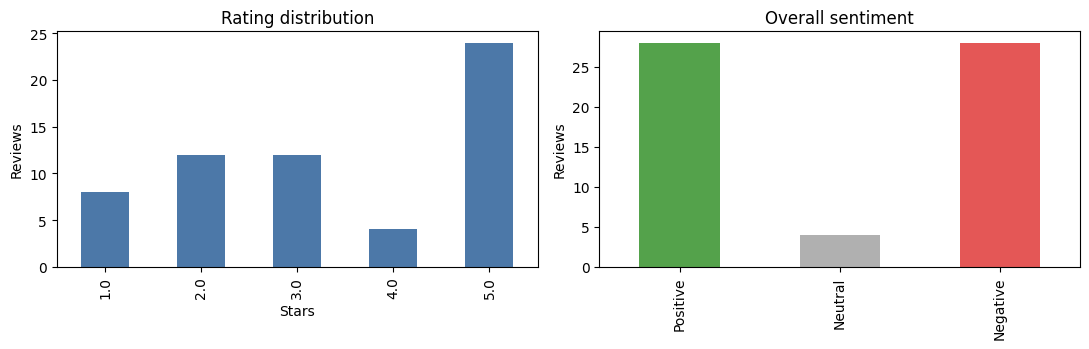

Polarity,Pos,Neu,Neg,Total,Net_Sentiment_%
Aspect,,,,,
Build Quality,8,0,12,20,-20.0
Design & Look,12,4,0,16,75.0
Performance,4,4,4,12,0.0
Value for Money,4,0,8,12,-33.3
Ease of Use,12,0,0,12,100.0
Battery,4,0,4,8,0.0
Durability,0,0,8,8,-100.0
Delivery & Packaging,0,0,8,8,-100.0
Customer Service,4,0,4,8,0.0


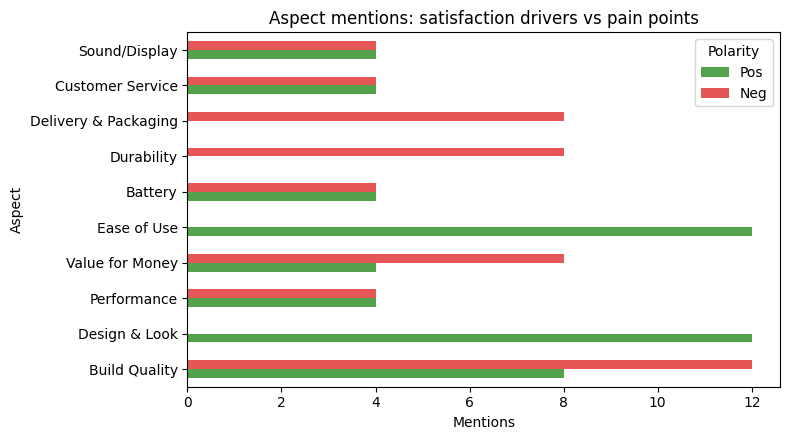

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
df["Rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C78A8")
axes[0].set_title("Rating distribution"); axes[0].set_xlabel("Stars"); axes[0].set_ylabel("Reviews")
df["Overall_Sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"]).plot(
    kind="bar", ax=axes[1], color=["#54A24B", "#B0B0B0", "#E45756"])
axes[1].set_title("Overall sentiment"); axes[1].set_xlabel(""); axes[1].set_ylabel("Reviews")
plt.tight_layout(); plt.show()

# Aspect-level drivers: count positive vs negative mentions per aspect
rows = []
for tags in df["Aspect_Sentiment"]:
    for t in tags:
        m = re.match(r"(?:Good|Poor|Average) (.+) \((Pos|Neg|Neu)\)", t)
        if m:
            rows.append({"Aspect": m.group(1), "Polarity": m.group(2)})
asp = pd.DataFrame(rows)
pivot = (asp.groupby(["Aspect", "Polarity"]).size().unstack(fill_value=0)
         .reindex(columns=["Pos", "Neu", "Neg"], fill_value=0))
pivot["Total"] = pivot.sum(axis=1)
pivot["Net_Sentiment_%"] = ((pivot["Pos"] - pivot["Neg"]) / pivot["Total"] * 100).round(1)
pivot = pivot.sort_values("Total", ascending=False)
display(pivot)

pivot[["Pos", "Neg"]].plot(kind="barh", figsize=(8, 4.5), color=["#54A24B", "#E45756"])
plt.title("Aspect mentions: satisfaction drivers vs pain points"); plt.xlabel("Mentions"); plt.tight_layout(); plt.show()

In [13]:
# Top drivers to quote in the report
print("Top satisfaction drivers (highest net sentiment):")
print(pivot[pivot["Total"] >= 3].sort_values("Net_Sentiment_%", ascending=False).head(3)[["Pos", "Neg", "Net_Sentiment_%"]], "\n")
print("Top dissatisfaction drivers (lowest net sentiment):")
print(pivot[pivot["Total"] >= 3].sort_values("Net_Sentiment_%").head(3)[["Pos", "Neg", "Net_Sentiment_%"]])

# Sanity check: does the model agree with stars? (stars >=4 should mostly be Positive)
print("\nSentiment by star rating:")
print(pd.crosstab(df["Rating"], df["Overall_Sentiment"]))

Top satisfaction drivers (highest net sentiment):
Polarity          Pos  Neg  Net_Sentiment_%
Aspect                                     
Ease of Use        12    0            100.0
Design & Look      12    0             75.0
Customer Service    4    4              0.0 

Top dissatisfaction drivers (lowest net sentiment):
Polarity              Pos  Neg  Net_Sentiment_%
Aspect                                         
Durability              0    8           -100.0
Delivery & Packaging    0    8           -100.0
Value for Money         4    8            -33.3

Sentiment by star rating:
Overall_Sentiment  Negative  Neutral  Positive
Rating                                        
1.0                       8        0         0
2.0                      12        0         0
3.0                       8        4         0
4.0                       0        0         4
5.0                       0        0        24


## 8. Handling anti-scraping blockers (summary for the report)

| Challenge | Approach used / recommended |
|---|---|
| **Detection as a bot** | Real browser (Selenium) with a normal window size and `en-CA` locale; randomised human-like delays; scroll elements into view before clicking; low request volume. |
| **Rate limits / HTTP 429 / transient failures** | `with_retries`: exponential backoff with jitter (2s, 4s, 8s...). Honour any `Retry-After` header if seen. |
| **IP blocking** | Keep volume low. For larger legitimate jobs, use a reputable rotating proxy pool (residential or datacenter) with per-session sticky IPs, and rotate only after a block signal. |
| **CAPTCHA** | This notebook **stops and alerts** rather than bypassing. Options: solve manually in the headed browser and resume; reduce speed; or use the retailer's official API or data partnership. Automated CAPTCHA-solving services may breach site terms, so they are not recommended. |
| **Dynamic / lazy-loaded content** | Explicit scrolling and "Show More" clicking, with a cap on clicks and a check for the button disappearing. |
| **Layout changes breaking selectors** | Selectors are centralised in `SELECTORS` with multiple fallbacks. Add a unit test that fails if zero reviews parse. |
| **Duplicates across filters** | Primary key from the review id, else a content hash, then `drop_duplicates`. |
| **Compliance** | `robots.txt` check (fails closed), public data only, no login, review the site's Terms of Use, store only fields needed. |
| **Resumability** | Save raw CSV after each run; extend with periodic checkpointing for very large products. |